# [Open in Colab](https://colab.research.google.com/github/dmochow/BME-i9400-2026/blob/main/labs/lab01_regression.ipynb)

# BME i9400 — Lab 1
## A Regression Baseline for Body Fat

**Fall 2026 · Released Monday, October 5 · Notebook due Tuesday, October 14, 11:59 AM EST · Defense quiz Wednesday, October 14, in class**

In this lab you carry out a complete regression study on your own: prepare a dataset, fit and
regularise a linear model, choose between models on validation data, evaluate the choice once on a
test set, and report the result. The methods are those of Meetings 6 and 7. The dataset is new.

**How the lab is assessed.** The lab component of the course is 20% of the grade, over three labs.
Within a lab, the in-class defense quiz counts 70% and the submitted notebook 30%.

- **The notebook** is graded on whether it runs from top to bottom without error, whether every task
  is complete and correct, and on the quality of the report in section 8.
- **The defense quiz** is a ten-minute written quiz at the start of Meeting 10, taken closed-book: no
laptop, no notes, no AI tools. It asks you to explain and justify what is in *your* notebook: why a step was taken, what a
  number means, what would have happened otherwise. Section 9 describes it.

**Generative AI is permitted and expected** on the notebook. Use it as you would in practice: to
write code, to debug, to check your understanding. You are responsible for every line you submit,
and the defense tests whether you can account for it without assistance. Record how you used AI in
section 9.

**Work individually.** Discussion of approach is encouraged; code and text must be your own.

---
## 1 — The question and the data

Body fat percentage is a measure of health that is difficult to measure directly. The reference
method in this dataset is underwater weighing: the subject is weighed in air and fully submerged,
body density is computed from the two weights, and body fat is estimated from density by Siri's
equation,

$$\text{body fat (\%)} = \frac{495}{\text{density}} - 450$$

Underwater weighing needs a tank, trained staff, and a cooperative subject. A tape measure and a
scale need none of these. The question of this lab is the question of Penrose, Nelson and Fisher
(*Medicine & Science in Sports & Exercise*, 1985): **how well can body fat be predicted from
circumference measurements, weight, height, and age?**

### The data

252 men, measured at the Human Performance Research Center, Brigham Young University; the data were
made public by Johnson, "Fitting Percentage of Body Fat to Simple Body Measurements", *Journal of
Statistics Education*, 1996, with permission for non-commercial use. The course copy is
`data/bodyfat.csv`, one row per man.

| Column | Meaning | Units |
|---|---|---|
| `case` | identifier, 1 to 252 | |
| `body_fat_pct` | **the target**: body fat from Siri's equation | % |
| `density` | body density from underwater weighing | g/cm³ |
| `age` | age | years |
| `weight_lb` | weight | pounds |
| `height_in` | height | inches |
| `bmi` | body mass index, computed from weight and height | kg/m² |
| `neck`, `chest`, `abdomen`, `hip`, `thigh`, `knee`, `ankle`, `biceps`, `forearm`, `wrist` | circumferences | cm |

The documentation that accompanies the data states that it is "as received" and contains "a few
errors". Finding them is part of section 2.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "figure.dpi": 110})

URL  = "https://raw.githubusercontent.com/dmochow/BME-i9400-2026/main/data/bodyfat.csv"
data = pd.read_csv(URL)

circumferences = ["neck", "chest", "abdomen", "hip", "thigh", "knee", "ankle", "biceps", "forearm", "wrist"]
measurements   = ["age", "weight_lb", "height_in", "bmi"] + circumferences      # everything a clinic can measure
target         = "body_fat_pct"

print(f"{len(data)} men, {data.shape[1]} columns")
data.describe().T[["mean", "std", "min", "max"]].round(2)

252 men, 17 columns


,mean,std,min,max
case,126.50,72.89,1.0,252.00
body_fat_pct,19.15,8.37,0.0,47.50
density,1.06,0.02,1.0,1.11
age,44.88,12.60,22.0,81.00
weight_lb,178.92,29.39,118.5,363.15
height_in,70.15,3.66,29.5,77.75
bmi,25.44,3.65,18.1,48.90
neck,37.99,2.43,31.1,51.20
chest,100.82,8.43,79.3,136.20
abdomen,92.56,10.78,69.4,148.10


---
## 2 — Data readiness

Before any model is fitted, two questions from Meeting 1: are the values plausible, and is every
column one that would be available when the model is used?

### 2.1 Implausible values

The summary table above already shows at least two impossible values. Write code that finds every
row in which **height is below 50 inches** or **body fat is at most 0%**, and look at those rows in
full. Then decide what to do with each one — correct it, remove it, or keep it — and state the
decision and the reason in the answer cell. A decision without a reason receives no credit.

> Removing a row because it is inconvenient is not a reason. A value that is physically impossible,
> or that the documentation identifies as a recording error, is. The `bmi` column, which was
> computed from weight and height before the error was made, is evidence about what the height
> should have been.

In [2]:
# --- TODO: find the implausible rows ---
suspect = data[(data["height_in"] < 50) | (data["body_fat_pct"] <= 0)]

assert suspect is not None, "Fill in suspect."
assert len(suspect) >= 2 and ((suspect["height_in"] < 50) | (suspect["body_fat_pct"] <= 0)).all(), \
    "suspect should hold exactly the rows that meet one of the two conditions."
suspect

,case,body_fat_pct,density,age,weight_lb,height_in,bmi,neck,chest,abdomen,hip,thigh,knee,ankle,biceps,forearm,wrist
41,42,32.9,1.0250,44,205.0,29.5,29.9,36.6,106.0,104.3,115.5,70.6,42.5,23.7,33.6,28.7,17.4
181,182,0.0,1.1089,40,118.5,68.0,18.1,33.8,79.3,69.4,85.0,47.2,33.5,20.2,27.7,24.6,16.5


In [3]:
# --- TODO: apply your decisions, producing the DataFrame `clean` ---
clean = data.copy()

# 1. Correct the height typo for Case 42 (Index 41)
# BMI = (weight_lb / height_in**2) * 703 -> height_in = sqrt((weight_lb * 703) / BMI)
# sqrt((205.0 * 703) / 29.9) ≈ 69.5
clean.loc[41, 'height_in'] = 69.5

# 2. Drop Case 182 (Index 181) as 0% body fat (and negative Siri value) is physically impossible
clean = clean.drop(index=181)

assert clean is not None, "Produce the DataFrame clean."
assert set(clean.columns) == set(data.columns) and len(clean) <= len(data), "clean should keep the same columns."
print(f"{len(clean)} men remain after your decisions ({len(data) - len(clean)} removed)")

251 men remain after your decisions (1 removed)


**Answer 2.1** — For each row you flagged: what is wrong, what you did, and why. *The height does not match up correctly with the BMI for row 41. A new height was calculated using the BMI and weight in order to correct the value. Row 181 has a body fat percentage of 0 and even when recalculating the body fat percentage using the formula the value is -3.6% which is impossible. That row is dropped as a result.*

### 2.2 The column that must not be used

One column in this file is not a measurement a clinic could take with a scale and a tape measure,
and it is related to the target by a formula. Identify it, and demonstrate what happens when it is
included as a feature: fit a least squares model on all 14 measurements with and without that
column, on the full cleaned dataset, and compare the two values of $R^2$.

> Using a feature that is computed from the target, or that would only be known once the target is
> known, is called **target leakage**. The resulting model looks excellent and is useless, because
> the feature will not exist when the model is applied to a new person. Leakage of this kind is one
> of the most common ways in which a published model fails in practice (Meeting 1).

In [4]:
from sklearn.linear_model import LinearRegression

leaky_column = 'density'

# --- TODO: fit on the 14 measurements plus the leaky column, and on the 14 measurements alone ---
# Features with the leaky column
X_with = clean[measurements + [leaky_column]].values
y = clean[target].values
model_with = LinearRegression().fit(X_with, y)
r2_with = model_with.score(X_with, y)

# Features without the leaky column (measurements alone)
X_without = clean[measurements].values
model_without = LinearRegression().fit(X_without, y)
r2_without = model_without.score(X_without, y)

assert leaky_column is not None, "Fill in leaky_column."
assert leaky_column in clean.columns and leaky_column not in measurements + ["case", target], \
    "Name the column that is neither a clinic measurement, nor the identifier, nor the target."
assert r2_with is not None and r2_without is not None, "Fit both models."
print(f"R^2 with {leaky_column}: {r2_with:.3f}     without: {r2_without:.3f}")
assert r2_with > 0.95 > r2_without, "Including the leaky column should make the fit nearly perfect."

R^2 with density: 0.979     without: 0.745


**Answer 2.2** — Which column leaks, why (cite the formula), and why a model that used it would fail in a
clinic. *Density is related to the body fat percentage through the Siri equation and is a measurement that can not be taken in clinic in standard conditions. As described above, density is computed from the subject's weights to get the body fat percentage and would make the model fit seem better than it is considering the aim is to predict body fat percentage with easily accessed clinical settings.*

---
## 3 — Splitting the data

Three sets are needed: a **training set** to fit weights, a **validation set** to choose between
models and to choose $\lambda$, and a **test set** that is touched exactly once, in section 7.

> The training and validation sets together are called the **development set**: everything that may
> be used while the model is being built.

The test split is fixed below so that every student's test set is the same 63 men. The validation
split inside the development set is yours to make; use a fixed `random_state` so that your notebook
is reproducible.

In [5]:
from sklearn.model_selection import train_test_split

X_all = clean[measurements].values
y_all = clean[target].values

# Done for you: the test set, 25% of the men, identical for every student.
X_dev, X_test, y_dev, y_test = train_test_split(X_all, y_all, test_size=0.25, random_state=9400)

# --- TODO: split the development set into training and validation sets (about 25% validation) ---
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, random_state=42)

assert X_train is not None, "Make the validation split."
assert len(X_train) + len(X_val) == len(X_dev) and len(X_val) >= 0.2 * len(X_dev), \
    "Validation should be about a quarter of the development set."
print(f"training {len(y_train)}   validation {len(y_val)}   test {len(y_test)}")
print(f"body fat in the training set: mean {y_train.mean():.1f}%, standard deviation {y_train.std(ddof=1):.1f}%")

training 141   validation 47   test 63
body fat in the training set: mean 19.1%, standard deviation 8.3%


---
## 4 — The least squares baseline

Fit ordinary least squares on all 14 measurements, by the normal equations or with
`LinearRegression` (if you use both, verify that they agree). Report:

- RMSE and $R^2$ on the training and validation sets, in units of body fat percentage points
- the RMSE of the model that predicts the training mean for everyone, which any model must beat
- the fitted weights, each with its units (percentage points of body fat per year, per pound, per
  inch, per kg/m², per centimetre)
- a plot of the residuals against the fitted values on the training set

Then read the weights. Several have signs opposite to the correlation of their feature with body
fat. Compute the correlation matrix of the 14 measurements and use it to explain why, in the answer
cell (Meeting 7, section 4).

predict-the-mean baseline, validation RMSE: 7.83 percentage points
least squares:  training RMSE 3.97  R^2 0.772   |   validation RMSE 4.32  R^2 0.694

Fitted weights:
Intercept: -107.1229%
age         :   0.0090 %/year
weight_lb   :  -0.3340 %/lb
height_in   :   0.9008 %/in
bmi         :   1.0857 %/(kg/m²)
neck        :  -0.2968 %/cm
chest       :   0.0661 %/cm
abdomen     :   1.0333 %/cm
hip         :  -0.2967 %/cm
thigh       :   0.3874 %/cm
knee        :   0.2774 %/cm
ankle       :  -0.2503 %/cm
biceps      :   0.2352 %/cm
forearm     :   0.4452 %/cm
wrist       :  -0.8462 %/cm


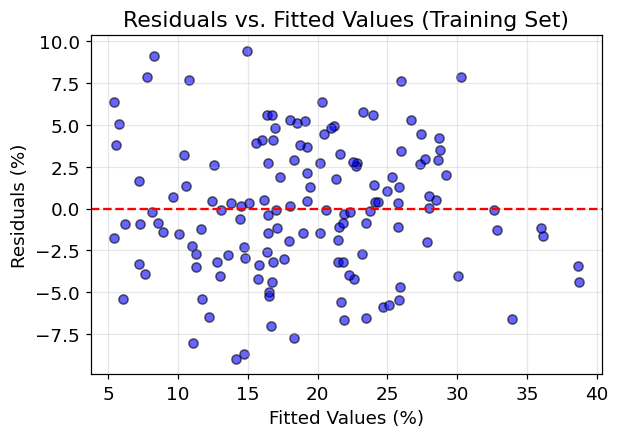


Correlations with body_fat_pct:
age          0.291
weight_lb    0.605
height_in   -0.034
bmi          0.722
neck         0.483
chest        0.696
abdomen      0.810
hip          0.618
thigh        0.550
knee         0.499
ankle        0.254
biceps       0.487
forearm      0.349
wrist        0.335
dtype: float64


In [6]:
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred)**2))

def r_squared(y_true, y_pred):
    return 1 - np.sum((y_true - y_pred)**2) / np.sum((y_true - y_true.mean())**2)

from sklearn.linear_model import LinearRegression

# --- TODO: fit least squares on all 14 measurements ---
ols = LinearRegression().fit(X_train, y_train)
pred_train_ols = ols.predict(X_train)
pred_val_ols = ols.predict(X_val)

assert pred_train_ols is not None and pred_val_ols is not None, "Fit the model and predict both sets."
baseline_rmse = rmse(y_val, np.full_like(y_val, y_train.mean(), dtype=float))
print(f"predict-the-mean baseline, validation RMSE: {baseline_rmse:.2f} percentage points")
print(f"least squares:  training RMSE {rmse(y_train, pred_train_ols):.2f}  R^2 {r_squared(y_train, pred_train_ols):.3f}"
      f"   |   validation RMSE {rmse(y_val, pred_val_ols):.2f}  R^2 {r_squared(y_val, pred_val_ols):.3f}")
assert rmse(y_val, pred_val_ols) < baseline_rmse, "The model should beat the mean."

# --- TODO: print each weight with its units; plot residuals against fitted values; show the correlations ---
units = {
    "age": "%/year",
    "weight_lb": "%/lb",
    "height_in": "%/in",
    "bmi": "%/(kg/m²)"
}

print("\nFitted weights:")
print(f"Intercept: {ols.intercept_:.4f}%")
for feature, coef in zip(measurements, ols.coef_):
    unit = units.get(feature, "%/cm")
    print(f"{feature:12}: {coef:8.4f} {unit}")

# Plot residuals
residuals = y_train - pred_train_ols
plt.figure(figsize=(6, 4))
plt.scatter(pred_train_ols, residuals, alpha=0.6, color='blue', edgecolor='k')
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Fitted Values (%)")
plt.ylabel("Residuals (%)")
plt.title("Residuals vs. Fitted Values (Training Set)")
plt.grid(True, alpha=0.3)
plt.show()

# Correlations with target
correlations = clean[measurements].corrwith(clean[target])
print("\nCorrelations with body_fat_pct:")
print(correlations.round(3))

**Answer 4** — Which weights have a sign opposite to their feature's correlation with body fat, and why.
*The weights with a sign opposite to their correlation are weight, neck, hip, wrist, and height. The reasoning behind this is that the sign is assigned when looking at that parameter alone and holding the other measurements constant. The example of this would be weight increasing but all other measurements remaining the same being indicative of denser fat-free mass like muscle or bone.*

---
## 5 — Ridge regression

Standardise the 14 measurements with the **training-set** mean and standard deviation, fit ridge
regression over a grid of $\lambda$ (`sklearn.linear_model.Ridge(alpha=...)`, or your own
implementation from Meeting 7), and:

- plot the validation RMSE against $\lambda$ on a logarithmic axis, and report the $\lambda$ that
  minimises it
- plot the weights against $\lambda$ (the coefficient paths), and say which weights the penalty
  shrinks first and why

> `Ridge(alpha=λ)` uses the convention of Meeting 7: a penalty on the weights, none on the intercept.

best lambda: 0.01    validation RMSE there: 4.32    (least squares: 4.32)


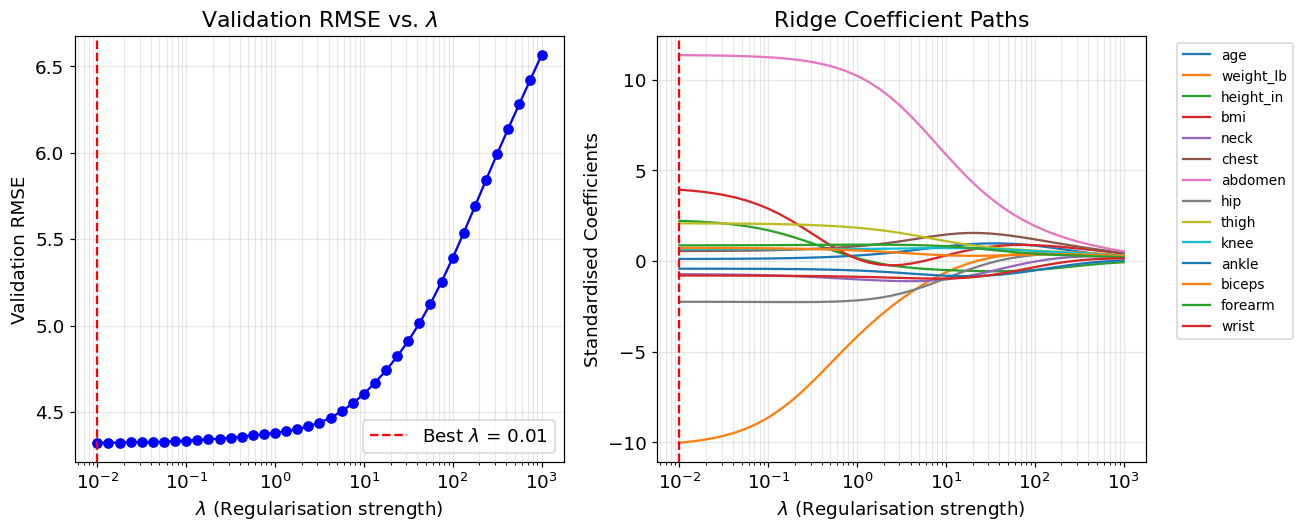

In [7]:
from sklearn.linear_model import Ridge

# Compute training-set mean and standard deviation of each measurement
mu = np.mean(X_train, axis=0)
sd = np.std(X_train, axis=0, ddof=1)

# Standardise features
Z_train = (X_train - mu) / sd
Z_val = (X_val - mu) / sd

lambdas = np.logspace(-2, 3, 41)

# Arrays to collect results
val_rmse = []
weights = []

for l in lambdas:
    model = Ridge(alpha=l)
    model.fit(Z_train, y_train)
    pred_val = model.predict(Z_val)

    val_rmse.append(rmse(y_val, pred_val))
    weights.append(model.coef_)

val_rmse = np.array(val_rmse)
weights = np.array(weights)
best_idx = np.argmin(val_rmse)
best_lambda = lambdas[best_idx]

assert Z_train is not None and np.allclose(Z_train.mean(axis=0), 0, atol=1e-8), "Standardise with the training statistics."
assert val_rmse is not None and len(val_rmse) == len(lambdas) and best_lambda is not None, "Fill in the sweep."
print(f"best lambda: {best_lambda:.3g}    validation RMSE there: {np.min(val_rmse):.2f}    (least squares: {rmse(y_val, pred_val_ols):.2f})")

# Plot 1: Validation RMSE vs. Lambda
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.semilogx(lambdas, val_rmse, marker='o', color='blue')
plt.axvline(best_lambda, color='red', linestyle='--', label=rf'Best $\lambda$ = {best_lambda:.2f}')
plt.xlabel(r"$\lambda$ (Regularisation strength)")
plt.ylabel("Validation RMSE")
plt.title(r"Validation RMSE vs. $\lambda$")
plt.grid(True, which="both", ls="-", alpha=0.3)
plt.legend()

# Plot 2: Weight paths vs. Lambda
plt.subplot(1, 2, 2)
for i, feature in enumerate(measurements):
    plt.semilogx(lambdas, weights[:, i], label=feature)
plt.axvline(best_lambda, color='red', linestyle='--')
plt.xlabel(r"$\lambda$ (Regularisation strength)")
plt.ylabel("Standardised Coefficients")
plt.title("Ridge Coefficient Paths")
plt.grid(True, which="both", ls="-", alpha=0.3)
# Position legend outside of plot for readability
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

**Answer 5** — Which $\lambda$ you chose and how; which weights the penalty shrinks first and why.
*Using the np.logspace function to create a list of possible lambdas and evaluating it against a training model, the best lambda of 0.01 is chosen for the minimization of the RMSE. Weight and abdomen experience the greatest magnitude of decline while it seems weight and BMI are the ones that start shrinking first. Part of the reason these shrink together would be the correlation between the two values and the other part would be the model assigns a larger penalty to unstable weights in order to stabilize itself.*

---
## 6 — A parsimonious model

A clinic would rather take three measurements than thirteen. Choose **at most three** of the 14
measurements, fit least squares on them, and compare the validation RMSE with the full model and
with ridge. Justify the choice with evidence from your notebook — correlations with the target,
correlations among the features, the weights — not with intuition alone.

> There is no single correct answer. A choice that is defended with evidence and evaluated honestly
> is correct; a choice that happens to score well is not.

In [8]:
# --- TODO: choose up to three measurements and fit least squares on them ---
chosen         = ["abdomen", "weight_lb", "wrist"]                  # a list of 1 to 3 column names from `measurements`
small          = LinearRegression().fit(X_train[:, [measurements.index(c) for c in chosen]], y_train)                  # the fitted model
pred_val_small = small.predict(X_val[:, [measurements.index(c) for c in chosen]])

assert chosen is not None and 1 <= len(chosen) <= 3 and all(c in measurements for c in chosen), "Choose 1 to 3 measurements."
assert pred_val_small is not None, "Fit the model and predict the validation set."
print(f"{chosen}: validation RMSE {rmse(y_val, pred_val_small):.2f}   "
      f"(full least squares {rmse(y_val, pred_val_ols):.2f}, ridge {np.min(val_rmse):.2f}, mean {baseline_rmse:.2f})")

['abdomen', 'weight_lb', 'wrist']: validation RMSE 4.27   (full least squares 4.32, ridge 4.32, mean 7.83)


**Answer 6** — Your choice of measurements and the evidence for it. *The measurements chosen are wrist, abdomen, and weight. Abdomen and weight have proven to be strongly correlated with body fat percentage at values of 0.81 and 0.61 respectively. Wrist is chosen as the third measurement choice in order to account for skeletal mass. It has a correlation value of 0.34 but a negative weight of -0.85 %/cm with the theory that a larger wrist with all other values remaining the same would be indicative of a larger skeleton.*

---
## 7 — The test set, once

Every decision has now been made on validation data: the data cleaning, $\lambda$, and the small
model. Refit each model on the **development set** — training and validation together — with its
chosen settings (standardise with the development set's statistics for ridge), and evaluate all of
them on the test set. Report, in one table:

| Model | Test RMSE | Test $R^2$ |
|---|---|---|
| predict the development-set mean | | |
| least squares, 14 measurements | | |
| ridge, $\lambda$ from section 5 | | |
| your model from section 6 | | |

and a plot of predicted against observed body fat on the test set for your preferred model. The test
set is not used again after this cell. If you change a model after seeing these numbers, the test
set is no longer a test set.

                           model  test RMSE  test R^2
predict the development-set mean      8.533    -0.000
  least squares, 14 measurements      5.015     0.655
         ridge, λ from section 5      5.010     0.655
       your model from section 6      4.643     0.704


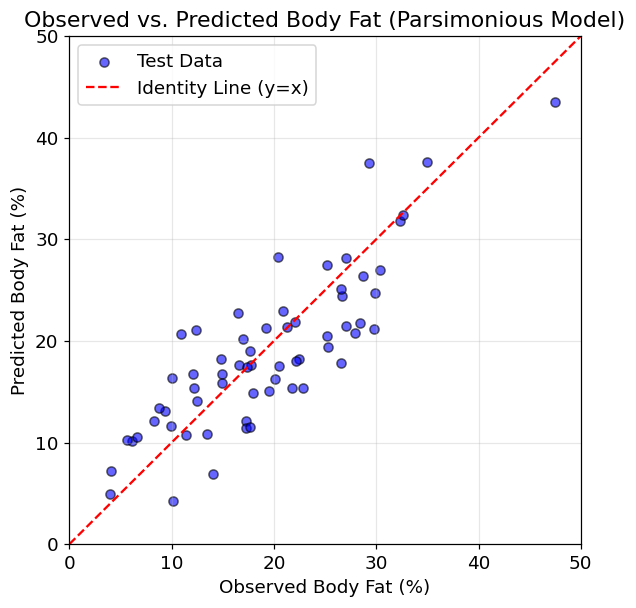

In [9]:
# --- TODO: refit each model on the development set and evaluate on the test set ---
# 1. Mean baseline
y_dev_mean = y_dev.mean()
pred_test_mean = np.full_like(y_test, y_dev_mean, dtype=float)
rmse_mean = rmse(y_test, pred_test_mean)
r2_mean = r_squared(y_test, pred_test_mean)

# 2. Least squares (14 measurements)
ols_full = LinearRegression().fit(X_dev, y_dev)
pred_test_ols = ols_full.predict(X_test)
rmse_ols = rmse(y_test, pred_test_ols)
r2_ols = r_squared(y_test, pred_test_ols)

# 3. Ridge (lambda = 0.01)
mu_dev = np.mean(X_dev, axis=0)
sd_dev = np.std(X_dev, axis=0, ddof=1)
Z_dev = (X_dev - mu_dev) / sd_dev
Z_test = (X_test - mu_dev) / sd_dev

ridge_model = Ridge(alpha=best_lambda)
ridge_model.fit(Z_dev, y_dev)
pred_test_ridge = ridge_model.predict(Z_test)
rmse_ridge = rmse(y_test, pred_test_ridge)
r2_ridge = r_squared(y_test, pred_test_ridge)

# 4. Your model (3 measurements: 'abdomen', 'weight_lb', 'wrist')
chosen_idx = [measurements.index(c) for c in chosen]
X_dev_small = X_dev[:, chosen_idx]
X_test_small = X_test[:, chosen_idx]

small_model = LinearRegression().fit(X_dev_small, y_dev)
pred_test_small = small_model.predict(X_test_small)
rmse_small = rmse(y_test, pred_test_small)
r2_small = r_squared(y_test, pred_test_small)

results = pd.DataFrame({
    "model": [
        "predict the development-set mean",
        "least squares, 14 measurements",
        "ridge, \u03bb from section 5",
        "your model from section 6"
    ],
    "test RMSE": [rmse_mean, rmse_ols, rmse_ridge, rmse_small],
    "test R^2": [r2_mean, r2_ols, r2_ridge, r2_small]
})

assert results is not None and len(results) == 4, "Four rows: mean, least squares, ridge, your model."
print(results.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

# --- TODO: predicted against observed on the test set, with the diagonal ---
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_test_small, color='blue', alpha=0.6, edgecolor='k', label='Test Data')
plt.plot([0, 50], [0, 50], color='red', linestyle='--', label='Identity Line (y=x)')
plt.xlim(0, 50)
plt.ylim(0, 50)
plt.xlabel("Observed Body Fat (%)")
plt.ylabel("Predicted Body Fat (%)")
plt.title("Observed vs. Predicted Body Fat (Parsimonious Model)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

---
## 8 — Report

Write the report in the cell below, in at most 300 words, under these headings. It is read by someone
who has not seen the rest of the notebook.

1. **The task.** What a row of $X$ is, what $y$ is, and what population the data describe.
2. **Data decisions.** What you changed or removed before fitting, and why.
3. **Results.** The table of section 7, with one sentence of interpretation per row.
4. **Two weights.** Interpret two weights of the full model, with units, including one whose sign is
   opposite to its correlation with body fat.
5. **Limitations.** Who the model should not be applied to, and why; what the known data errors
   might have done to the weights.
6. **Recommendation.** Which measurements a clinic should take, and what error to expect.

### Report

**1. The task.** *Each row, X, is comprised of an individual's data and every column, Y, corresponds to what type of data it is. The population described are men that volunteered at BYU.*

**2. Data decisions.** *Density was ignored, as a computed value would be an identifier that would make the models predictions more accurate than it would realistically be. One individual's data was removed due to the body fat percentage (BF%) calculated being impossible to obtain and a height for another was recalculated due to a mismatch between it and the BMI recorded.*

**3. Results.** *The first model attempts to predict BF% without looking at any measurement and as results has no variance accounted for. The second model accounts for clinical measurements and comes up with a RMSE of 5.015% but accounts for 65.5% of the variance in BF%. The third model accounts for the same amount of variance in BF% but with a lower RMSE at 5.010%. The final model accounts for 70.4% of variance with the lowest RMSE of 4.643%.*

**4. Two weights.** *The neck has a positive correlation of 0.483 with a weight of -0.2968 %/cm. A larger neck would typically indicate a higher BF% outside of all other measurements staying the same which would indicate a lower BF%. The abdomen has a positive correlation of 0.81 and a weight of 1.0333 %/cm. Any increase in size to the abdomen indicates a higher BF%.*

**5. Limitations.** *This model consists of men that volunteered for measurement at BYU. Thus, it would not be appropriate to use this model on women or children and expect accurate results. Weights may be skewed incorrectly depending on input errors as outliers are significant in least squares.*

**6. Recommendation.** *A clinic should measure the patient's weight and the circumference of their abdomen and wrist. The first two correlate strongly with BF% and the latter may account for skeletal mass. The RMSE expected would be 4.643% and other errors in practice could be attributed to outliers or denser muscle mass.*

---
## 9 — AI use, submission, and the defense

### AI use statement

In the cell below, list the AI tools you used and what for — code, debugging, explanation, writing —
in two to five lines. The statement is not graded for its content; its absence costs credit.

**AI use statement** — *Gemini was used to aid in coding/plotting for several sections and for debugging errors. Gemini was also used to explain the code contributed and to give hints as to what may run the corresponding section correctly.*

### Submitting

**Due Tuesday, October 13, at 11:59 PM EST.**

1. `Runtime ▸ Restart session and run all`. Every cell must run without error, and every check must
   pass.
2. `File ▸ Download ▸ Download .ipynb`.
3. Rename the file to `YOUR-GITHUB-USERNAME_lab01.ipynb` and move it into the `checkins/` folder of
   your clone.
4. Commit in GitHub Desktop, push, and open a pull request.

Late notebooks are accepted for 48 hours with a 20% penalty on the notebook portion. The defense quiz
cannot be made up except for a documented excused absence (syllabus).

### The defense quiz — Wednesday, October 14, Meeting 10

Ten minutes, written, at the start of the meeting, closed-book: laptops closed, no notes, no AI tools.
You will not have your notebook in front of you, so know its contents before you arrive, including your
main results to about two significant figures. Five or six short questions about your own notebook,
each answerable in two or three sentences. The kinds of question to expect:

- why a step was necessary — why the features are standardised before ridge, why the test set is
  used once
- what a number means — your test RMSE, in its units, against the predict-the-mean baseline
- what a weight means, and why its sign can disagree with the feature's correlation with the target
- what would have happened under a different choice — if `density` had been kept, or if $\lambda$ had
  been chosen on the test set

Each question is scored 0, 1 or 2. Prepare by being able to explain every cell of your notebook
without looking at it.